Using device: cuda


Processing...
Done!



Dataset: Computers  (13752 nodes, 10 classes)

--- Computers | split 60-20-20 | 4578s elapsed ---
GCN                     66.07 ±  0.70
GAT                     66.96 ±  2.39
GATv2                   55.66 ±  4.56
APPNP                   65.11 ±  0.64
GPRGNN                  88.41 ±  0.70
TAG                     81.41 ±  0.66
GEN                     80.77 ± 22.80
GCNII                   75.13 ±  1.07
GENTAG (Proposed)       91.06 ±  0.79

--- Computers | split 70-15-15 | 9152s elapsed ---
GCN                     66.27 ±  0.88
GAT                     67.26 ±  4.49
GATv2                   55.56 ±  4.21
APPNP                   65.33 ±  0.46
GPRGNN                  87.89 ±  0.75
TAG                     81.67 ±  0.74
GEN                     85.53 ± 16.92
GCNII                   71.14 ±  7.51
GENTAG (Proposed)       91.02 ±  0.67

--- Computers | split 80-10-10 | 13748s elapsed ---
GCN                     66.46 ±  1.13
GAT                     64.34 ±  3.53
GATv2                   55.45 ±  3.6

,60-20-20,70-15-15,80-10-10
GCN,66.07 ± 0.70,66.27 ± 0.88,66.46 ± 1.13
GAT,66.96 ± 2.39,67.26 ± 4.49,64.34 ± 3.53
GATv2,55.66 ± 4.56,55.56 ± 4.21,55.45 ± 3.60
APPNP,65.11 ± 0.64,65.33 ± 0.46,65.23 ± 0.87
GPRGNN,88.41 ± 0.70,87.89 ± 0.75,88.54 ± 0.74
TAG,81.41 ± 0.66,81.67 ± 0.74,81.55 ± 0.85
GEN,80.77 ± 22.80,85.53 ± 16.92,86.00 ± 17.13
GCNII,75.13 ± 1.07,71.14 ± 7.51,73.06 ± 6.61
GENTAG (Proposed),91.06 ± 0.79,91.02 ± 0.67,91.54 ± 0.59


Results saved to results_computers.json


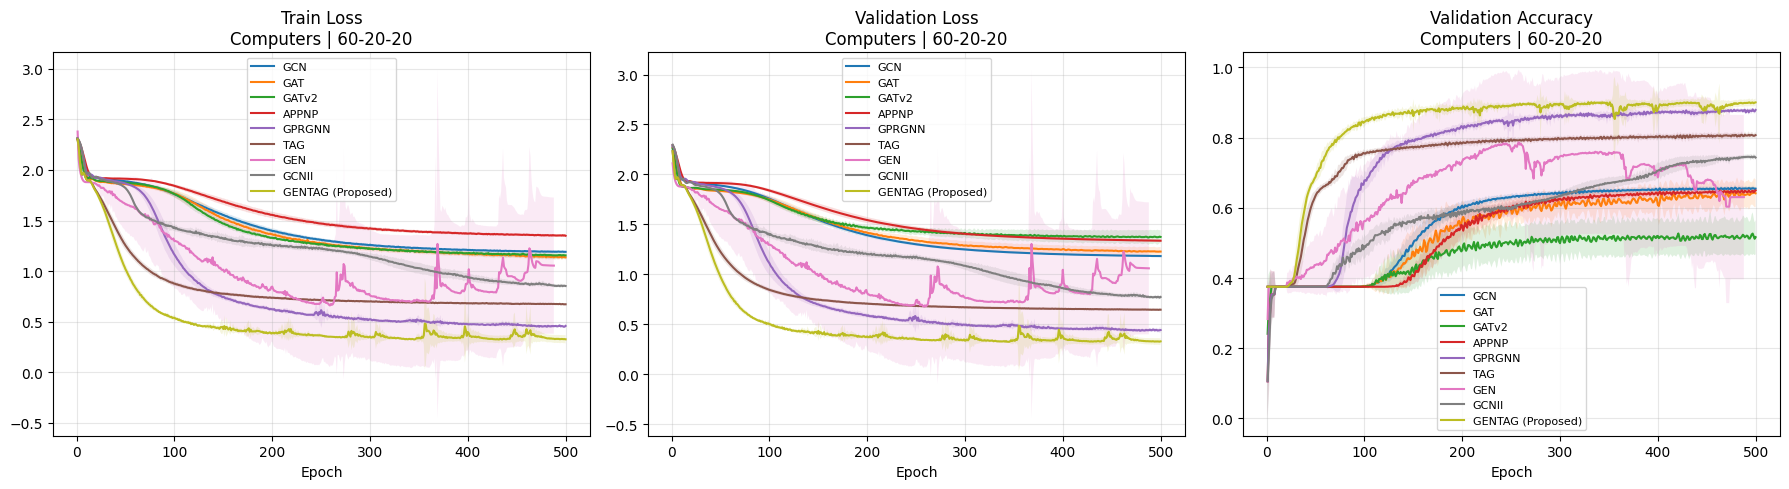

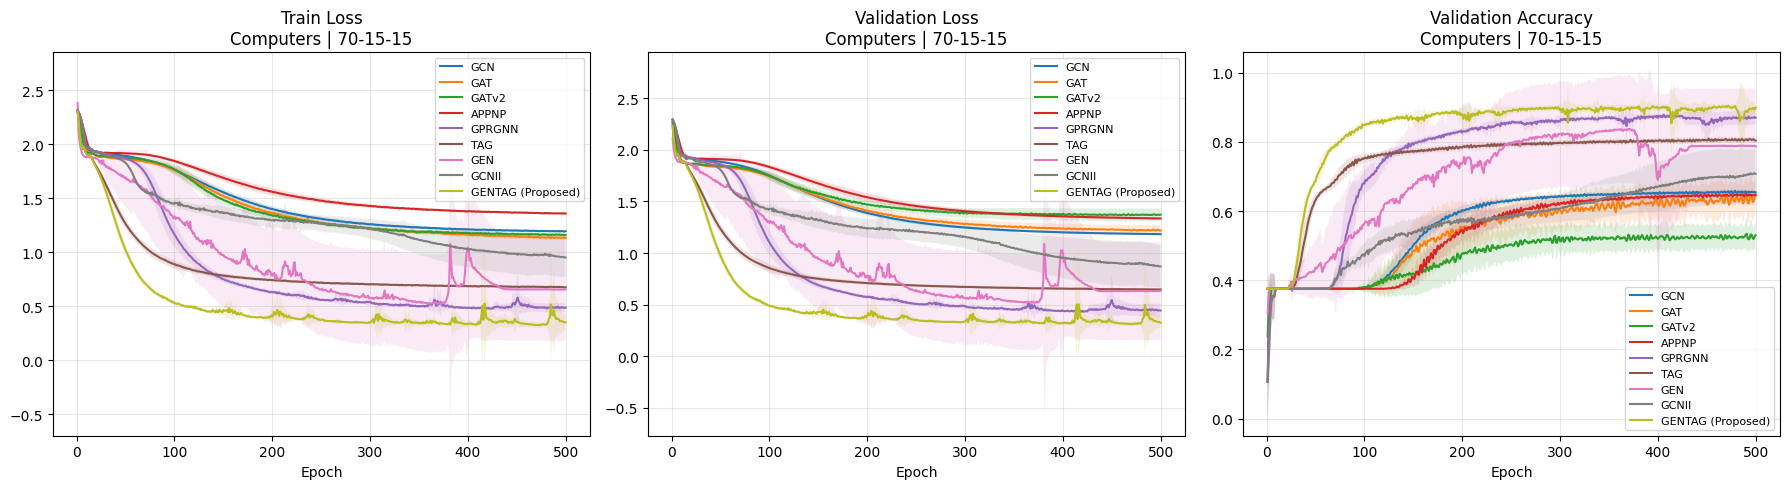

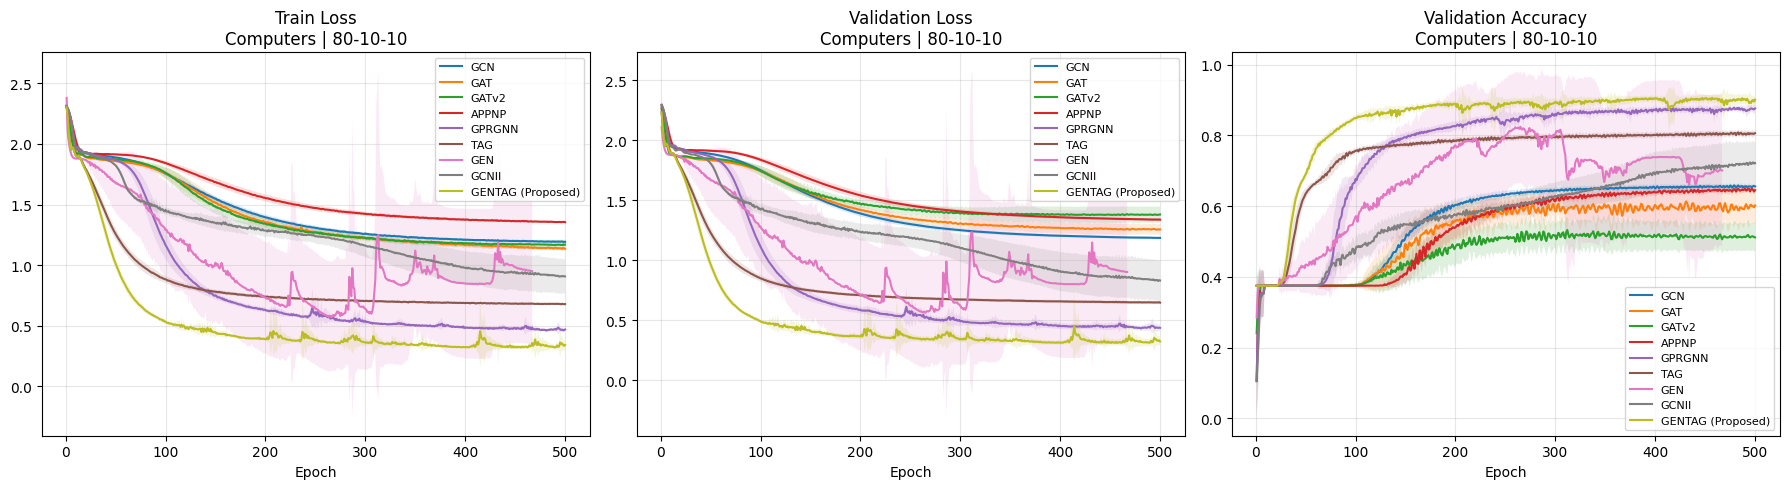

In [ ]:
! pip install torch_geometric
import os
import random
import json
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn import Linear
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

from torch_geometric.datasets import Amazon
from torch_geometric.transforms import NormalizeFeatures
from torch_geometric.nn import (
    GCNConv, GATConv, GATv2Conv,
    APPNP, TAGConv, GENConv, GCN2Conv
)
from torch_geometric.nn.conv import MessagePassing
from torch_geometric.nn.conv.gcn_conv import gcn_norm
from torch_geometric.nn.inits import zeros
from torch_geometric.utils import spmm, to_undirected

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

SEED = 42

# ---------- hyper-parameters (identical for every model) ----------
HIDDEN_DIM = 64
DROPOUT = 0.5
LR = 0.01
WEIGHT_DECAY = 5e-4
MAX_EPOCHS = 500
PATIENCE = 50
NUM_RUNS = 10

# ---------- fairness switches ----------
INPUT_DROPOUT = True
MATCH_GAT_WIDTH = True
SELECT_BY = 'val_loss'
NO_DECAY_HOP_COEFS = True
MAKE_UNDIRECTED = False

# ---------- architecture constants ----------
K_TAG = 3
K_APPNP = 10
K_GPR = 10
ALPHA_APPNP = 0.1
ALPHA_GPR = 0.1
ALPHA_GCN2 = 0.1
THETA_GCN2 = 0.5
GCNII_LAYERS = 2
HEADS = 4


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


# ------------------------------------------------------------
# GENTAG layer
# ------------------------------------------------------------
class TAGConv1(MessagePassing):
    def __init__(self, in_channels, out_channels, K=3, bias=True, normalize=True,
                 use_mlp=False, use_message_relu=True, eps=1e-7, **kwargs):
        kwargs.setdefault('aggr', 'add')
        super().__init__(**kwargs)

        self.K = K
        self.normalize = normalize
        self.use_mlp = use_mlp
        self.use_message_relu = use_message_relu
        self.eps = eps

        self.lins = nn.ModuleList([
            Linear(in_channels, out_channels, bias=False) for _ in range(K + 1)
        ])
        self.comb = nn.Parameter(torch.ones(K + 1))

        if bias:
            self.bias = nn.Parameter(torch.zeros(out_channels))
        else:
            self.register_parameter('bias', None)

        self.mlp = nn.Sequential(Linear(out_channels, out_channels), nn.ReLU()) if use_mlp else nn.Identity()
        self.reset_parameters()

    def reset_parameters(self):
        for lin in self.lins:
            lin.reset_parameters()
        nn.init.ones_(self.comb)
        if self.bias is not None:
            zeros(self.bias)

    def forward(self, x, edge_index, edge_weight=None):
        if self.normalize:
            edge_index, edge_weight = gcn_norm(
                edge_index, edge_weight, x.size(self.node_dim),
                improved=False, add_self_loops=False,
                flow=self.flow, dtype=x.dtype
            )

        out = self.comb[0] * self.lins[0](x)
        h = x
        for k in range(1, self.K + 1):
            h = self.propagate(edge_index, x=h, edge_weight=edge_weight)
            out = out + self.comb[k] * self.lins[k](h)

        if self.bias is not None:
            out = out + self.bias
        return self.mlp(out)

    def message(self, x_j, edge_weight):
        msg = x_j if edge_weight is None else edge_weight.view(-1, 1) * x_j
        if self.use_message_relu:
            return msg.relu() + self.eps
        return msg

    def message_and_aggregate(self, adj_t, x):
        return spmm(adj_t, x, reduce=self.aggr)


# ------------------------------------------------------------
# GPR-GNN propagation
# ------------------------------------------------------------
class GPR_prop(MessagePassing):
    def __init__(self, K, alpha=0.1, Init='PPR', Gamma=None, **kwargs):
        super().__init__(aggr='add', **kwargs)
        self.K = K
        self.Init = Init
        self.alpha = alpha
        self.Gamma = Gamma

        assert Init in ['SGC', 'PPR', 'NPPR', 'Random', 'WS']
        if Init == 'SGC':
            TEMP = torch.zeros(K + 1)
            TEMP[K] = 1.0
        elif Init == 'PPR':
            TEMP = alpha * (1 - alpha) ** torch.arange(K + 1, dtype=torch.float)
            TEMP[-1] = (1 - alpha) ** K
        elif Init == 'NPPR':
            TEMP = alpha ** torch.arange(K + 1, dtype=torch.float)
            TEMP = TEMP / torch.sum(torch.abs(TEMP))
        elif Init == 'Random':
            bound = np.sqrt(3 / (K + 1))
            TEMP = torch.rand(K + 1) * 2 * bound - bound
            TEMP = TEMP / torch.sum(torch.abs(TEMP))
        elif Init == 'WS':
            TEMP = Gamma.clone().float()

        self.temp = nn.Parameter(TEMP)

    def reset_parameters(self):
        torch.nn.init.zeros_(self.temp)
        if self.Init == 'SGC':
            self.temp.data[self.K] = 1.0
        elif self.Init == 'PPR':
            for k in range(self.K + 1):
                self.temp.data[k] = self.alpha * (1 - self.alpha) ** k
            self.temp.data[-1] = (1 - self.alpha) ** self.K
        elif self.Init == 'NPPR':
            for k in range(self.K + 1):
                self.temp.data[k] = self.alpha ** k
            self.temp.data = self.temp.data / torch.sum(torch.abs(self.temp.data))
        elif self.Init == 'Random':
            bound = np.sqrt(3 / (self.K + 1))
            torch.nn.init.uniform_(self.temp, -bound, bound)
            self.temp.data = self.temp.data / torch.sum(torch.abs(self.temp.data))
        elif self.Init == 'WS':
            self.temp.data = self.Gamma.clone().float()

    def forward(self, x, edge_index, edge_weight=None):
        edge_index, norm = gcn_norm(
            edge_index, edge_weight, num_nodes=x.size(0), dtype=x.dtype)

        hidden = x * self.temp[0]
        for k in range(self.K):
            x = self.propagate(edge_index, x=x, norm=norm)
            hidden = hidden + self.temp[k + 1] * x
        return hidden

    def message(self, x_j, norm):
        return norm.view(-1, 1) * x_j


def apply_input_dropout(x, training):
    return F.dropout(x, p=DROPOUT, training=training) if INPUT_DROPOUT else x


class GCN(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels):
        super().__init__()
        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, out_channels)

    def forward(self, x, edge_index):
        x = apply_input_dropout(x, self.training)
        x = F.relu(self.conv1(x, edge_index))
        x = F.dropout(x, p=DROPOUT, training=self.training)
        return self.conv2(x, edge_index)


class GAT(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, heads=HEADS):
        super().__init__()
        per_head = max(hidden_channels // heads, 1) if MATCH_GAT_WIDTH else hidden_channels
        self.conv1 = GATConv(in_channels, per_head, heads=heads, dropout=DROPOUT)
        self.conv2 = GATConv(per_head * heads, out_channels, heads=1, concat=False, dropout=DROPOUT)

    def forward(self, x, edge_index):
        x = apply_input_dropout(x, self.training)
        x = F.relu(self.conv1(x, edge_index))
        x = F.dropout(x, p=DROPOUT, training=self.training)
        return self.conv2(x, edge_index)


class GATv2(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, heads=HEADS):
        super().__init__()
        per_head = max(hidden_channels // heads, 1) if MATCH_GAT_WIDTH else hidden_channels
        self.conv1 = GATv2Conv(in_channels, per_head, heads=heads, dropout=DROPOUT)
        self.conv2 = GATv2Conv(per_head * heads, out_channels, heads=1, concat=False, dropout=DROPOUT)

    def forward(self, x, edge_index):
        x = apply_input_dropout(x, self.training)
        x = F.relu(self.conv1(x, edge_index))
        x = F.dropout(x, p=DROPOUT, training=self.training)
        return self.conv2(x, edge_index)


class APPNPNet(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels):
        super().__init__()
        self.lin1 = nn.Linear(in_channels, hidden_channels)
        self.lin2 = nn.Linear(hidden_channels, out_channels)
        self.prop = APPNP(K=K_APPNP, alpha=ALPHA_APPNP)

    def forward(self, x, edge_index):
        x = apply_input_dropout(x, self.training)
        x = self.lin1(x).relu()
        x = F.dropout(x, p=DROPOUT, training=self.training)
        x = self.lin2(x)
        return self.prop(x, edge_index)


class GPRGNN(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels):
        super().__init__()
        self.lin1 = Linear(in_channels, hidden_channels)
        self.lin2 = Linear(hidden_channels, out_channels)
        self.prop = GPR_prop(K=K_GPR, alpha=ALPHA_GPR, Init='PPR')

    def forward(self, x, edge_index):
        x = apply_input_dropout(x, self.training)
        x = self.lin1(x).relu()
        x = F.dropout(x, p=DROPOUT, training=self.training)
        x = self.lin2(x)
        return self.prop(x, edge_index)


class TAG(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels):
        super().__init__()
        self.conv1 = TAGConv(in_channels, hidden_channels, K=K_TAG)
        self.conv2 = TAGConv(hidden_channels, out_channels, K=K_TAG)

    def forward(self, x, edge_index):
        x = apply_input_dropout(x, self.training)
        x = F.relu(self.conv1(x, edge_index))
        x = F.dropout(x, p=DROPOUT, training=self.training)
        return self.conv2(x, edge_index)


class GEN(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels):
        super().__init__()
        self.conv1 = GENConv(in_channels, hidden_channels, aggr='softmax', t=1.0,
                             learn_t=True, num_layers=2, norm='layer')
        self.conv2 = GENConv(hidden_channels, out_channels, aggr='softmax', t=1.0,
                             learn_t=True, num_layers=2, norm='layer')

    def forward(self, x, edge_index):
        x = apply_input_dropout(x, self.training)
        x = F.relu(self.conv1(x, edge_index))
        x = F.dropout(x, p=DROPOUT, training=self.training)
        return self.conv2(x, edge_index)


class GCNII(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, num_layers=GCNII_LAYERS):
        super().__init__()
        self.lins = nn.ModuleList([
            nn.Linear(in_channels, hidden_channels),
            nn.Linear(hidden_channels, out_channels)
        ])
        self.convs = nn.ModuleList([
            GCN2Conv(hidden_channels, alpha=ALPHA_GCN2, theta=THETA_GCN2, layer=i + 1)
            for i in range(num_layers)
        ])

    def forward(self, x, edge_index):
        x = apply_input_dropout(x, self.training)
        x = x0 = self.lins[0](x).relu()
        for conv in self.convs:
            x = F.dropout(x, p=DROPOUT, training=self.training)
            x = conv(x, x0, edge_index).relu()
        x = F.dropout(x, p=DROPOUT, training=self.training)
        return self.lins[1](x)


class GENTAG(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, K=K_TAG):
        super().__init__()
        self.conv1 = TAGConv1(in_channels, hidden_channels, K=K,
                              use_mlp=False, use_message_relu=True, eps=1e-7)
        self.conv2 = TAGConv1(hidden_channels, out_channels, K=K,
                              use_mlp=False, use_message_relu=True, eps=1e-7)

    def forward(self, x, edge_index):
        x = apply_input_dropout(x, self.training)
        x = F.relu(self.conv1(x, edge_index))
        x = F.dropout(x, p=DROPOUT, training=self.training)
        return self.conv2(x, edge_index)


MODEL_DICT = {
    'GCN': GCN,
    'GAT': GAT,
    'GATv2': GATv2,
    'APPNP': APPNPNet,
    'GPRGNN': GPRGNN,
    'TAG': TAG,
    'GEN': GEN,
    'GCNII': GCNII,
    'GENTAG (Proposed)': GENTAG,
}


def make_optimizer(model, lr, weight_decay):
    decay, no_decay = [], []
    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        if NO_DECAY_HOP_COEFS and ('comb' in name or name.endswith('temp')):
            no_decay.append(param)
        else:
            decay.append(param)
    groups = [{'params': decay, 'weight_decay': weight_decay}]
    if no_decay:
        groups.append({'params': no_decay, 'weight_decay': 0.0})
    return torch.optim.Adam(groups, lr=lr)


def train_one_epoch(model, data, optimizer, criterion):
    model.train()
    optimizer.zero_grad()
    out = model(data.x, data.edge_index)
    loss = criterion(out[data.train_mask], data.y[data.train_mask])
    loss.backward()
    optimizer.step()
    return loss.item()


@torch.no_grad()
def evaluate(model, data, criterion):
    model.eval()
    out = model(data.x, data.edge_index)
    pred = out.argmax(dim=1)
    val_loss = criterion(out[data.val_mask], data.y[data.val_mask]).item()
    val_acc = (pred[data.val_mask] == data.y[data.val_mask]).float().mean().item()
    test_acc = (pred[data.test_mask] == data.y[data.test_mask]).float().mean().item()
    return val_loss, val_acc, test_acc


def run_with_early_stopping(model, data):
    optimizer = make_optimizer(model, LR, WEIGHT_DECAY)
    criterion = nn.CrossEntropyLoss()

    best = {'val_loss': float('inf'), 'val_acc': 0.0, 'test_acc': 0.0, 'epoch': 0}
    patience_counter = 0

    history = {
        'train_loss': [],
        'val_loss': [],
        'val_acc': []
    }

    for epoch in range(1, MAX_EPOCHS + 1):
        train_loss = train_one_epoch(model, data, optimizer, criterion)
        val_loss, val_acc, test_acc = evaluate(model, data, criterion)

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        improved = (val_loss < best['val_loss']) if SELECT_BY == 'val_loss' else (val_acc > best['val_acc'])
        if improved:
            best = {'val_loss': val_loss, 'val_acc': val_acc, 'test_acc': test_acc, 'epoch': epoch}
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= PATIENCE:
                break

    return best['val_acc'], best['test_acc'], history


# ------------------------------------------------------------
# Dataset helpers
# ------------------------------------------------------------
DATASETS = ['Computers']
SPLITS = {
    '60-20-20': (0.60, 0.20, 0.20),
    '70-15-15': (0.70, 0.15, 0.15),
    '80-10-10': (0.80, 0.10, 0.10),
}


def load_dataset(name):

    return Amazon(root=f'./data/{name}', name=name, transform=NormalizeFeatures())


def prepare_graph(data):
    if MAKE_UNDIRECTED:
        data.edge_index = to_undirected(data.edge_index, num_nodes=data.num_nodes)
    return data


def safe_stratify(y):
    counts = np.bincount(y)
    counts = counts[counts > 0]
    return y if counts.min() >= 2 else None


def create_random_split(data, ratios, seed):
    train_ratio, val_ratio, test_ratio = ratios
    n = data.num_nodes
    indices = np.arange(n)
    y = data.y.cpu().numpy()

    train_val_idx, test_idx = train_test_split(
        indices, test_size=test_ratio, random_state=seed, stratify=safe_stratify(y)
    )
    train_idx, val_idx = train_test_split(
        train_val_idx,
        test_size=val_ratio / (train_ratio + val_ratio),
        random_state=seed,
        stratify=safe_stratify(y[train_val_idx])
    )

    data = data.clone()
    for mask_name, idx in [('train_mask', train_idx), ('val_mask', val_idx), ('test_mask', test_idx)]:
        mask = torch.zeros(n, dtype=torch.bool)
        mask[idx] = True
        setattr(data, mask_name, mask)
    return data


def get_data(raw_data, ratios, run):
    data = raw_data.clone()
    if ratios is None:
        for mask_name in ('train_mask', 'val_mask', 'test_mask'):
            mask = getattr(data, mask_name)
            if mask.dim() == 2:
                setattr(data, mask_name, mask[:, run % mask.size(1)])
    else:
        data = create_random_split(data, ratios, SEED + run)
    return data.to(device)


# ------------------------------------------------------------
# Main experiment
# ------------------------------------------------------------
all_results = {}
all_histories = {}
t0 = time.time()

for ds_name in DATASETS:
    dataset = load_dataset(ds_name)
    raw_data = prepare_graph(dataset[0])
    all_results[ds_name] = {}
    all_histories[ds_name] = {}

    print(f"\n{'=' * 70}")
    print(f"Dataset: {ds_name}  ({raw_data.num_nodes} nodes, {dataset.num_classes} classes)")
    print(f"{'=' * 70}")

    for split_name, ratio in SPLITS.items():
        split_results = {name: [] for name in MODEL_DICT}
        split_histories = {name: [] for name in MODEL_DICT}

        for run in range(NUM_RUNS):
            data = get_data(raw_data, ratio, run)

            for model_name, ModelClass in MODEL_DICT.items():
                set_seed(SEED + run)
                model = ModelClass(dataset.num_features, HIDDEN_DIM, dataset.num_classes).to(device)
                _, test_acc, history = run_with_early_stopping(model, data)

                split_results[model_name].append(test_acc * 100)
                split_histories[model_name].append(history)

            del data
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        all_results[ds_name][split_name] = {}
        all_histories[ds_name][split_name] = split_histories

        print(f"\n--- {ds_name} | split {split_name} | {time.time() - t0:.0f}s elapsed ---")
        for model_name, accs in split_results.items():
            accs = np.array(accs)
            mean, std = float(accs.mean()), float(accs.std(ddof=1))
            all_results[ds_name][split_name][model_name] = (mean, std)
            print(f"{model_name:<22} {mean:6.2f} ± {std:5.2f}")


def show_tables(results):
    for ds, per_split in results.items():
        df = pd.DataFrame({
            s: {m: f"{mu:.2f} ± {sd:.2f}" for m, (mu, sd) in d.items()}
            for s, d in per_split.items()
        })
        print(f"\n### {ds}   (test accuracy %, mean ± std over {NUM_RUNS} runs)")
        display(df)


show_tables(all_results)

with open('results_computers.json', 'w') as f:
    json.dump(all_results, f, indent=2)
print("Results saved to results_computers.json")


# ------------------------------------------------------------
# Plot average curves
# ------------------------------------------------------------
def pad_and_average(histories, key):
    max_len = max(len(h[key]) for h in histories)
    padded = []
    for h in histories:
        arr = np.array(h[key])
        if len(arr) < max_len:
            arr = np.pad(arr, (0, max_len - len(arr)), mode='edge')
        padded.append(arr)
    return np.mean(padded, axis=0), np.std(padded, axis=0)


def plot_curves(histories_dict, dataset_name, split_name):
    models = list(histories_dict.keys())
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    metrics = [
        ('train_loss', 'Train Loss'),
        ('val_loss', 'Validation Loss'),
        ('val_acc', 'Validation Accuracy')
    ]

    for ax, (key, title) in zip(axes, metrics):
        for model_name in models:
            mean, std = pad_and_average(histories_dict[model_name], key)
            epochs = np.arange(1, len(mean) + 1)
            ax.plot(epochs, mean, label=model_name)
            ax.fill_between(epochs, mean - std, mean + std, alpha=0.15)
        ax.set_title(f"{title}\n{dataset_name} | {split_name}")
        ax.set_xlabel("Epoch")
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


for ds_name in all_histories:
    for split_name in all_histories[ds_name]:
        plot_curves(all_histories[ds_name][split_name], ds_name, split_name)